In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# Load the 'taxis' dataset
df = sns.load_dataset("taxis")

In [10]:
# Load the taxis dataset
df = sns.load_dataset("taxis")

df

,pickup,dropoff,passengers,distance,fare,tip,tolls,total,color,payment,pickup_zone,dropoff_zone,pickup_borough,dropoff_borough
0,2019-03-23 20:21:09,2019-03-23 20:27:24,1,1.60,7.0,2.15,0.0,12.95,yellow,credit card,Lenox Hill West,UN/Turtle Bay South,Manhattan,Manhattan
1,2019-03-04 16:11:55,2019-03-04 16:19:00,1,0.79,5.0,0.00,0.0,9.30,yellow,cash,Upper West Side South,Upper West Side South,Manhattan,Manhattan
2,2019-03-27 17:53:01,2019-03-27 18:00:25,1,1.37,7.5,2.36,0.0,14.16,yellow,credit card,Alphabet City,West Village,Manhattan,Manhattan
3,2019-03-10 01:23:59,2019-03-10 01:49:51,1,7.70,27.0,6.15,0.0,36.95,yellow,credit card,Hudson Sq,Yorkville West,Manhattan,Manhattan
4,2019-03-30 13:27:42,2019-03-30 13:37:14,3,2.16,9.0,1.10,0.0,13.40,yellow,credit card,Midtown East,Yorkville West,Manhattan,Manhattan
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6428,2019-03-31 09:51:53,2019-03-31 09:55:27,1,0.75,4.5,1.06,0.0,6.36,green,credit card,East Harlem North,Central Harlem North,Manhattan,Manhattan
6429,2019-03-31 17:38:00,2019-03-31 18:34:23,1,18.74,58.0,0.00,0.0,58.80,green,credit card,Jamaica,East Concourse/Concourse Village,Queens,Bronx
6430,2019-03-23 22:55:18,2019-03-23 23:14:25,1,4.14,16.0,0.00,0.0,17.30,green,cash,Crown Heights North,Bushwick North,Brooklyn,Brooklyn
6431,2019-03-04 10:09:25,2019-03-04 10:14:29,1,1.12,6.0,0.00,0.0,6.80,green,credit card,East New York,East Flatbush/Remsen Village,Brooklyn,Brooklyn


In [11]:
missing_values = df.isnull().sum()

print(missing_values[missing_values > 0])

payment            44
pickup_zone        26
dropoff_zone       45
pickup_borough     26
dropoff_borough    45
dtype: int64


In [12]:
numerical_columns = df.select_dtypes(
    include="number"
).columns

print(numerical_columns.tolist())

['passengers', 'distance', 'fare', 'tip', 'tolls', 'total']


In [13]:
for column in numerical_columns:
    median_value = df[column].median()
    df[column] = df[column].fillna(median_value)

print("Missing values in numerical columns after filling:")

print(df[numerical_columns].isnull().sum())

Missing values in numerical columns after filling:
passengers    0
distance      0
fare          0
tip           0
tolls         0
total         0
dtype: int64


In [14]:
categorical_columns = df.select_dtypes(
    include=["object", "category", "string"]
).columns

for column in categorical_columns:
    if df[column].isnull().any():
        mode_values = df[column].mode(dropna=True)

        if not mode_values.empty:
            df[column] = df[column].fillna(mode_values.iloc[0])

print("Missing values in categorical columns after filling:")
print(df[categorical_columns].isnull().sum())

Missing values in categorical columns after filling:
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


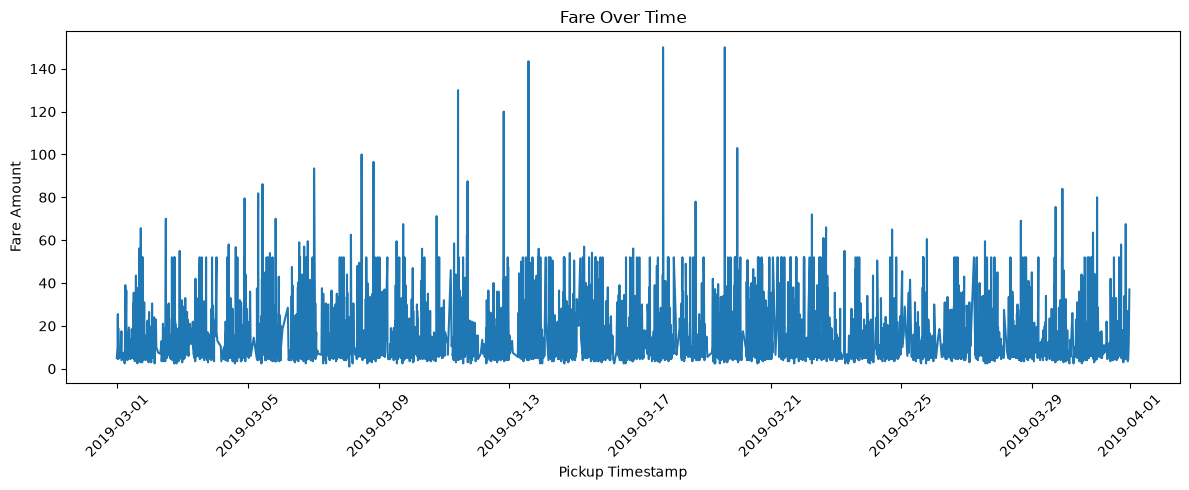

In [17]:
df = df.sort_values("pickup")

plt.figure(figsize=(12, 5))

plt.plot(df["pickup"], df["fare"])

plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare Amount")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

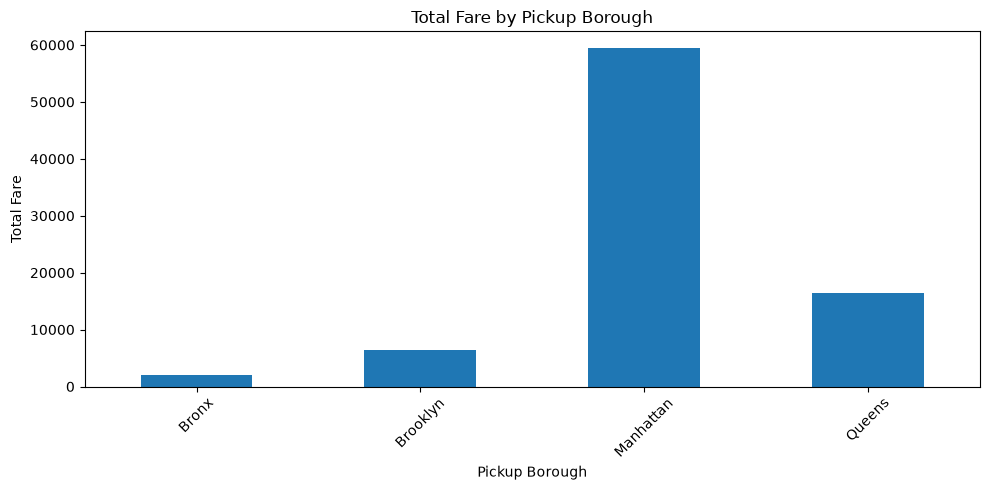

In [18]:
borough_fare = df.groupby(
    "pickup_borough", observed=True
)["fare"].sum()

borough_fare.plot(
    kind="bar",
    figsize=(10, 5),
    title="Total Fare by Pickup Borough"
)

plt.xlabel("Pickup Borough")
plt.ylabel("Total Fare")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

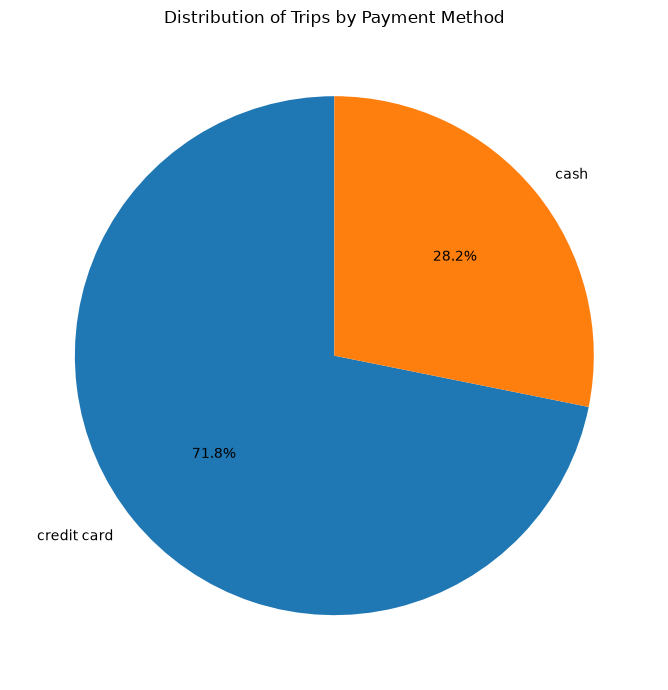

In [19]:
payment_counts = df["payment"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Trips by Payment Method")
plt.tight_layout()
plt.show()

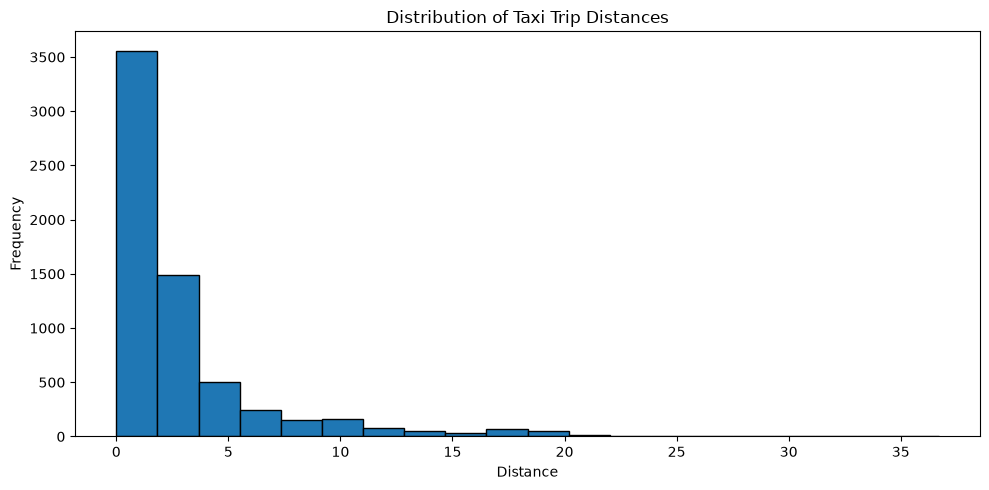

In [20]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["distance"],
    bins=20,
    edgecolor="black"
)

plt.title("Distribution of Taxi Trip Distances")
plt.xlabel("Distance")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

<Figure size 1000x500 with 0 Axes>

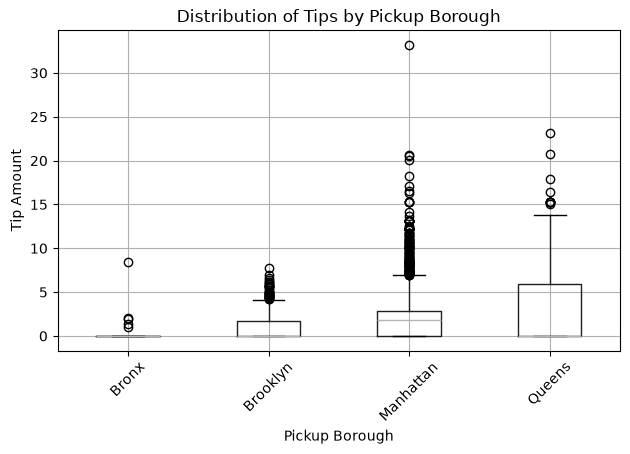

In [21]:
plt.figure(figsize=(10, 5))

df.boxplot(
    column="tip",
    by="pickup_borough"
)

plt.title("Distribution of Tips by Pickup Borough")
plt.suptitle("")
plt.xlabel("Pickup Borough")
plt.ylabel("Tip Amount")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

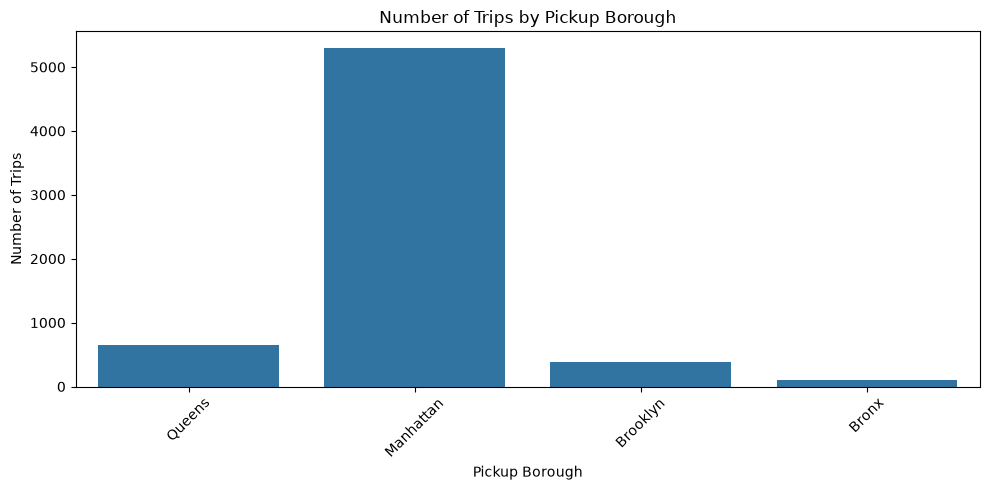

In [22]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x="pickup_borough")

plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Number of Trips")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

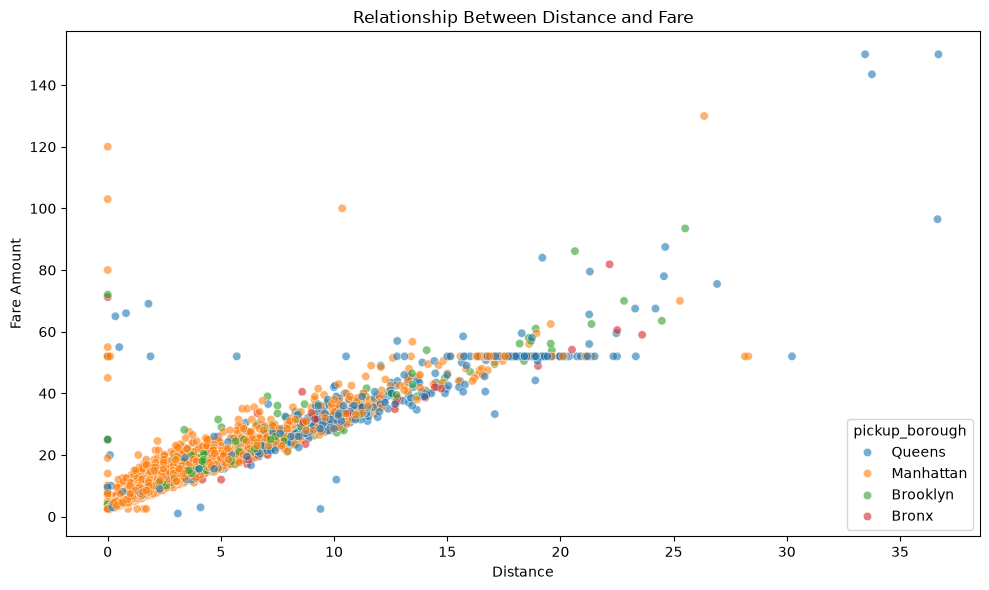

In [23]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="distance",
    y="fare",
    hue="pickup_borough",
    alpha=0.6
)

plt.title("Relationship Between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare Amount")

plt.tight_layout()
plt.show()

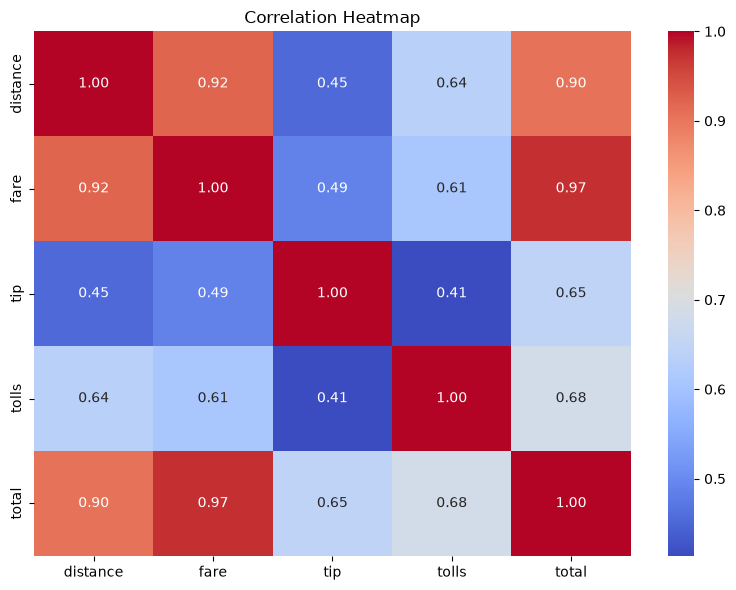

In [24]:
numeric_data = df[
    ["distance", "fare", "tip", "tolls", "total"]
]

correlation_matrix = numeric_data.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

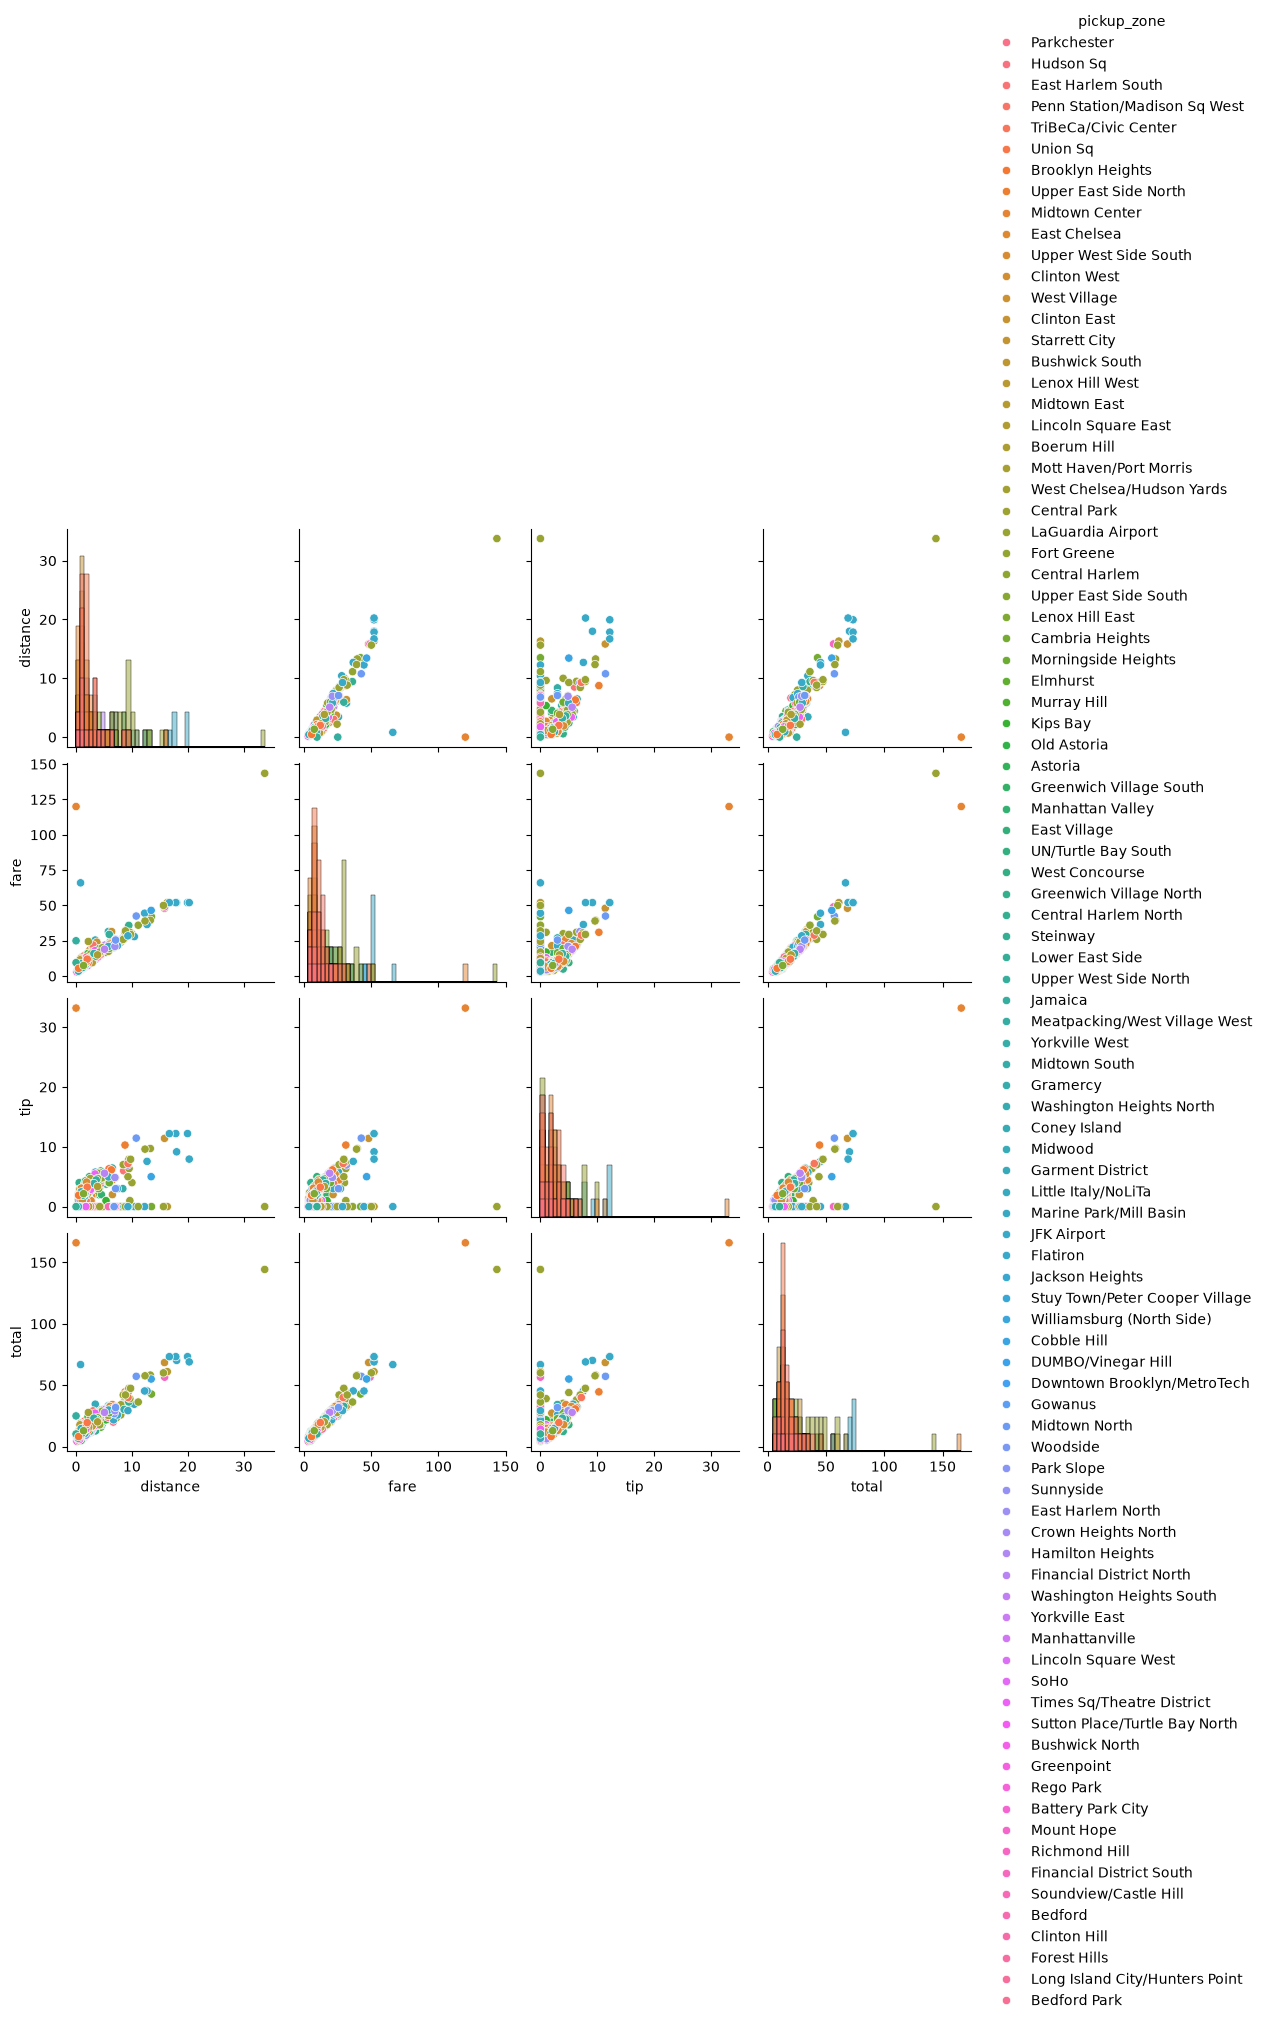

In [26]:
pair_data = df[
    ["distance", "fare", "tip", "total", "pickup_zone"]
].dropna()

# Use a sample to make the chart easier to display
pair_sample = pair_data.sample(
    n=min(500, len(pair_data)),
    random_state=42
)

sns.pairplot(
    pair_sample,
    vars=["distance", "fare", "tip", "total"],
    hue="pickup_zone",
    diag_kind="hist"
)

plt.show()

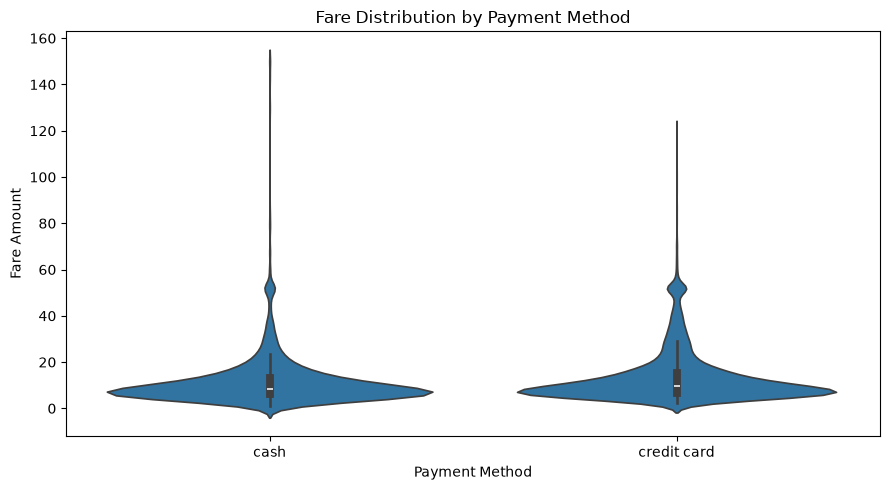

In [27]:
plt.figure(figsize=(9, 5))

sns.violinplot(
    data=df,
    x="payment",
    y="fare"
)

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Fare Amount")

plt.tight_layout()
plt.show()